In [2]:
import sys
sys.path.append("..")

In [3]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt 

In [5]:
df_ch_przeplyw = pd.read_parquet('../data/processed/Chorzów/przeplyw.parquet')
df_ch_scieki = pd.read_parquet('../data/processed/Chorzów/scieki.parquet')
df_ch_awarie = pd.read_parquet('../data/processed/Chorzów/awarie.parquet')
df_ch_energia = pd.read_parquet('../data/processed/Chorzów/energia.parquet')
df_ch_opady = pd.read_parquet('../data/processed/Chorzów/suma_opadow.parquet')

In [6]:
#MAD - mediana bezwzględnych odchyleń od mediany 
def mad(x):
    return np.median(np.abs(x-np.median(x)))

### IsolationForest
Algorytm uczenia nienadzorowanego, który służy do wykrywania anomalii, nietypowych zachowań (wykorzystuje losowe drzewa do izolowania nietypowych obserwacji -> umożliwia identyfikację nieprawidłowości z danych i wychodzi z założenia, że nietypowe obserwacje jest zazwyczaj łatwiej odizolować od pozostałych danych)

In [7]:
df = df_ch_scieki.copy()

df["Sposób_pomiaru"] = df["Sposób_pomiaru"].astype(str).str.strip()
df = df[df["Sposób_pomiaru"] == "Wartość z pomiaru"].copy()


if "Data_czas" in df.columns:
    df["Data_czas"] = pd.to_datetime(df["Data_czas"])
    df = df.set_index("Data_czas")

df = df.rename(columns={"Ilosc_przepompowanych_sciekow": "ilosc"})

# konwersja na liczbowe
df["ilosc"] = pd.to_numeric(
    df["ilosc"].astype(str).str.replace(",", ".", regex=False),
    errors="coerce"
)

# usuwanie zer i śmieci
df = df[df["ilosc"].notna()]

df = df.sort_index()
print(df.head())

                           Data   Godzina      ilosc     Sposób_pomiaru
Data_czas                                                              
2024-10-13 00:00:00  13.10.2024  00:00:00  4891880.0  Wartość z pomiaru
2024-10-13 00:00:54  13.10.2024  00:00:54  4891880.0  Wartość z pomiaru
2024-10-13 00:01:06  13.10.2024  00:01:06  4891880.0  Wartość z pomiaru
2024-10-13 00:01:18  13.10.2024  00:01:18  4891890.0  Wartość z pomiaru
2024-10-13 00:01:26  13.10.2024  00:01:26  4891890.0  Wartość z pomiaru


In [8]:
df = df[~df.index.duplicated(keep='last')].copy()
df = df.sort_index()

In [9]:
hourly = df["ilosc"].resample("1h").last()

df_1h = pd.DataFrame({
    "przepompowano": hourly.diff()
})

#żeby usunąć te ujemne wartości 
df_1h.loc[df_1h["przepompowano"] < 0, "przepompowano"] = np.nan
print(df_1h.head())

                     przepompowano
Data_czas                         
2024-10-13 00:00:00            NaN
2024-10-13 01:00:00           10.0
2024-10-13 02:00:00           20.0
2024-10-13 03:00:00           10.0
2024-10-13 04:00:00           20.0


In [10]:
#diff - oblicza różnicę między bieżącym wierszem, a poprzednim
df_1h["diff"] = df_1h["przepompowano"].diff()

#ewm - średnia krocząca
df_1h["ewm_3h"] = df_1h["przepompowano"].ewm(span=3, adjust=False).mean()
df_1h["ewm_12h"] = df_1h["przepompowano"].ewm(span=12, adjust=False).mean()

df_1h["rolling_mean_3h"] = df_1h["przepompowano"].rolling(3, min_periods=2).mean()
df_1h["rolling_mean_6h"] = df_1h["przepompowano"].rolling(6, min_periods=3).mean()
df_1h["rolling_mean_24h"] = df_1h["przepompowano"].rolling(24, min_periods=12).mean()


df_1h["rolling_min_6h"] = df_1h["przepompowano"].rolling(6, min_periods=3).min()
df_1h["rolling_max_6h"] = df_1h["przepompowano"].rolling(6, min_periods=3).max()
df_1h["rolling_std_6h"] = df_1h["przepompowano"].rolling(6, min_periods=3).std()

In [11]:
features = ["przepompowano", "diff", "ewm_3h", "ewm_12h", "rolling_mean_3h", "rolling_mean_6h", "rolling_mean_24h", "rolling_min_6h", "rolling_max_6h", "rolling_std_6h" ]

In [12]:
#isotree - ponieważ jest to bibliotrka z cpp, która zawiera ten wariant, a ten wariant jest odporny na ewentualne nany
#from isotree import IsolationForest 
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest

In [13]:
X = df_1h[features].copy()
X = X.dropna().sort_index()

#podział danych chronologicznie
split = int(len(df_1h)*0.7)

X_train = X.iloc[:split].copy()
X_test = X.iloc[split:].copy()

X_train = X_train.dropna(axis=1, how="all")
X_test = X_test[X_train.columns]

In [14]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

iso = IsolationForest(n_estimators=200, n_jobs=-1, random_state=42)

iso.fit(X_train_scaled)

,"n_estimators n_estimators: int, default=100The number of base estimators in the ensemble.",200
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for :meth:`fit`. ``None`` means 1unless in a :obj:`joblib.parallel_backend` context. ``-1`` means usingall processors. See :term:`Glossary <n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo-randomness of the selection of the featureand split values for each branching step and each tree in the forest.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",42
,"max_samples max_samples: ""auto"", int or float, default=""auto""The number of samples to draw from X to train each base estimator.- If int, then draw `max_samples` samples.- If float, then draw `max_samples * X.shape[0]` samples.- If ""auto"", then `max_samples=min(256, n_samples)`.If max_samples is larger than the number of samples provided,all samples will be used for all trees (no sampling).",'auto'
,"contamination contamination: 'auto' or float, default='auto'The amount of contamination of the data set, i.e. the proportionof outliers in the data set. Used when fitting to define the thresholdon the scores of the samples.- If 'auto', the threshold is determined as in the original paper.- If float, the contamination should be in the range (0, 0.5]... versionchanged:: 0.22 The default value of ``contamination`` changed from 0.1 to ``'auto'``.",'auto'
,"max_features max_features: int or float, default=1.0The number of features to draw from X to train each base estimator.- If int, then draw `max_features` features.- If float, then draw `max(1, int(max_features * n_features_in_))` features.Note: using a float number less than 1.0 or integer less than number offeatures will enable feature subsampling and leads to a longer runtime.",1.0
,"bootstrap bootstrap: bool, default=FalseIf True, individual trees are fit on random subsets of the trainingdata sampled with replacement. If False, sampling without replacementis performed.",False
,"verbose verbose: int, default=0Controls the verbosity of the tree building process.",0
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fitand add more estimators to the ensemble, otherwise, just fit a wholenew forest. See :term:`the Glossary <warm_start>`... versionadded:: 0.21",False
Name,Type,Value
estimator_ estimator_: :class:`~sklearn.tree.ExtraTreeRegressor` instanceThe child estimator template used to create the collection offitted sub-estimators... versionadded:: 1.2 `base_estimator_` was renamed to `estimator_`.,ExtraTreeRegressor,ExtraTreeRegr...ndom_state=42)


In [15]:
#dla isoforest to jak jest niższy score to nietypowa obserwacja i dlatego minus bo chcemy na odwrót
iso_scores_train = pd.Series(-iso.score_samples(X_train_scaled), index= X_train.index)
iso_scores_test = pd.Series(-iso.score_samples(X_test_scaled), index= X_test.index)

#isoforest ocenia każdą godzinę osobno, więc moga być zmienne te dane 
#smooth - dlatego wygładzamy, że uznajemy dłuższą anomalię jako coś podejrzanego 
#ograniczamy wpływ pojedynczych skoków 
scores = pd.concat([iso_scores_train, iso_scores_test]).sort_index()

smooth_scores = scores.ewm(span=3, adjust=False).mean()

smooth_train = smooth_scores.reindex(iso_scores_train.index)
smooth_test = smooth_scores.reindex(iso_scores_test.index)

In [16]:
def rolling_threshold(sm, window="30D", method="mad", k=4.0, min_periods = 24*7, step ="1h"):
    sm_step = sm.resample(step).mean()
    r = sm_step.rolling(window, min_periods, closed="left")

    if method == "mad":
        med = r.median()
        mad = (sm_step - med).abs().rolling(window, min_periods, closed="left").median()
        thr = med + k * 1.4826 * mad
    elif method == "tukey":
        q1, q3 = r.quantile(0.25), r.quantile(0.75)
        thr = q3 + 1.5 * (q3-q1)
    else: 
        raise ValueError

    return thr.reindex(sm.index, method="ffill")

In [17]:
thr_roll = rolling_threshold(smooth_scores)

threshold_test = thr_roll.reindex(smooth_test.index)
hot = smooth_test[smooth_test > threshold_test]

#grupujemy anomalie w alarmy, ponieważ przez 8h może wystąpić zwiększona ilość ścieków
#bez grupowania otrzymamy właśnie 8alarmów 
new_alarm = hot.index.to_series().diff() > pd.Timedelta("180min")
new_alarm.iloc[0] = True

alerts_df = pd.DataFrame({
    "datetime": hot.index[new_alarm.values],
    "anomaly_score": hot[new_alarm.values].values
})

print("Liczba alarmow: ", len(alerts_df))

Liczba alarmow:  43


In [24]:
print(df_1h.loc[
    "2026-06-03":"2026-06-05",
    ["przepompowano", "rolling_mean_6h", "rolling_mean_24h"]
].to_string())

                     przepompowano  rolling_mean_6h  rolling_mean_24h
Data_czas                                                            
2026-06-03 00:00:00           10.0        21.666667         17.916667
2026-06-03 01:00:00           10.0        20.000000         17.916667
2026-06-03 02:00:00           10.0        16.666667         17.916667
2026-06-03 03:00:00           10.0        15.000000         17.916667
2026-06-03 04:00:00            0.0        10.000000         17.916667
2026-06-03 05:00:00           10.0         8.333333         17.916667
2026-06-03 06:00:00           10.0         8.333333         17.916667
2026-06-03 07:00:00           20.0        10.000000         17.916667
2026-06-03 08:00:00           20.0        11.666667         17.916667
2026-06-03 09:00:00           30.0        15.000000         18.333333
2026-06-03 10:00:00           20.0        18.333333         18.333333
2026-06-03 11:00:00           20.0        20.000000         17.916667
2026-06-03 12:00:00 

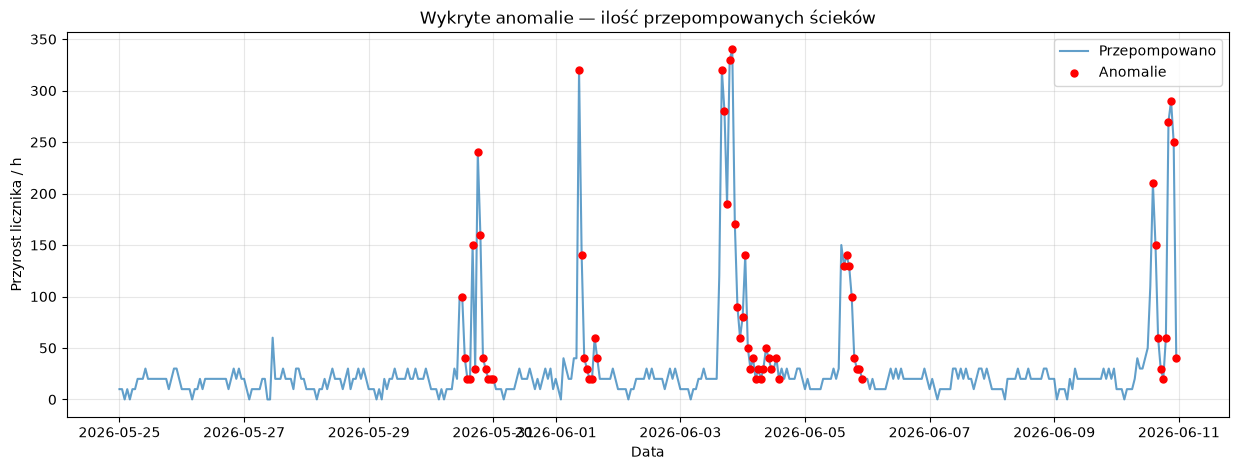

In [26]:
start = "2026-05-25"
end = "2026-06-10"

signal = df_1h.loc[X_test.index, "przepompowano"]
signal_period = signal.loc[start:end]

hot_period = hot.loc[start:end]

plt.figure(figsize=(15, 5))

plt.plot(
    signal_period.index,
    signal_period,
    label="Przepompowano",
    alpha=0.7
)

plt.scatter(
    hot_period.index,
    signal.reindex(hot_period.index),
    color="red",
    s=25,
    label="Anomalie",
    zorder=3
)

plt.title("Wykryte anomalie — ilość przepompowanych ścieków")
plt.xlabel("Data")
plt.ylabel("Przyrost licznika / h")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [21]:
df_ch_opady["Data_czas"] = pd.to_datetime(df_ch_opady["Data_czas"])
df_ch_opady = df_ch_opady.set_index("Data_czas")
df_ch_opady = df_ch_opady.sort_index()

df_ch_opady = df_ch_opady[~df_ch_opady.index.duplicated(keep="first")].copy()


In [22]:

df_ch_opady["opad_3h"] = df_ch_opady["suma_opadu_mm"].rolling(3, min_periods=3).sum()
df_ch_opady["opad_6h"] = df_ch_opady["suma_opadu_mm"].rolling(6, min_periods=6).sum()
df_ch_opady["opad_24h"] = df_ch_opady["suma_opadu_mm"].rolling(24, min_periods=24).sum()

print(df_ch_opady.head(10))

                     suma_opadu_mm  opad_3h  opad_6h  opad_24h
Data_czas                                                     
2024-01-01 00:00:00            0.0      NaN      NaN       NaN
2024-01-01 01:00:00            0.0      NaN      NaN       NaN
2024-01-01 02:00:00            0.0      0.0      NaN       NaN
2024-01-01 03:00:00            0.0      0.0      NaN       NaN
2024-01-01 04:00:00            0.0      0.0      NaN       NaN
2024-01-01 05:00:00            0.1      0.1      0.1       NaN
2024-01-01 06:00:00            0.2      0.3      0.3       NaN
2024-01-01 07:00:00            0.5      0.8      0.8       NaN
2024-01-01 08:00:00            0.7      1.4      1.5       NaN
2024-01-01 09:00:00            0.6      1.8      2.1       NaN


In [23]:
alerts_weather = alerts_df.copy()

alerts_weather = alerts_weather.join(
    df_ch_opady[["opad_3h", "opad_6h", "opad_24h"]],
    on="datetime"
)

print(alerts_weather.head(10))
print("Liczba alarmów:", len(alerts_weather))

             datetime  anomaly_score  opad_3h  opad_6h  opad_24h
0 2026-03-26 01:00:00       0.477431      1.2      1.3       1.3
1 2026-03-28 01:00:00       0.472681      1.0      1.6       2.9
2 2026-03-31 01:00:00       0.485914      1.3      1.3       1.3
3 2026-04-15 07:00:00       0.458496      0.0      0.1       1.1
4 2026-04-19 20:00:00       0.457026      1.8      1.8       1.8
5 2026-05-02 07:00:00       0.449775      0.0      0.0       0.0
6 2026-05-03 06:00:00       0.457773      0.0      0.0       0.0
7 2026-05-07 19:00:00       0.461747      0.1      0.6       0.7
8 2026-05-11 14:00:00       0.488456      0.2      0.2       8.0
9 2026-05-12 01:00:00       0.544522      0.0      0.0       8.8
Liczba alarmów: 43
